In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

Train Data

In [5]:
# load training dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

ds_train = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True)
print(ds_train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None


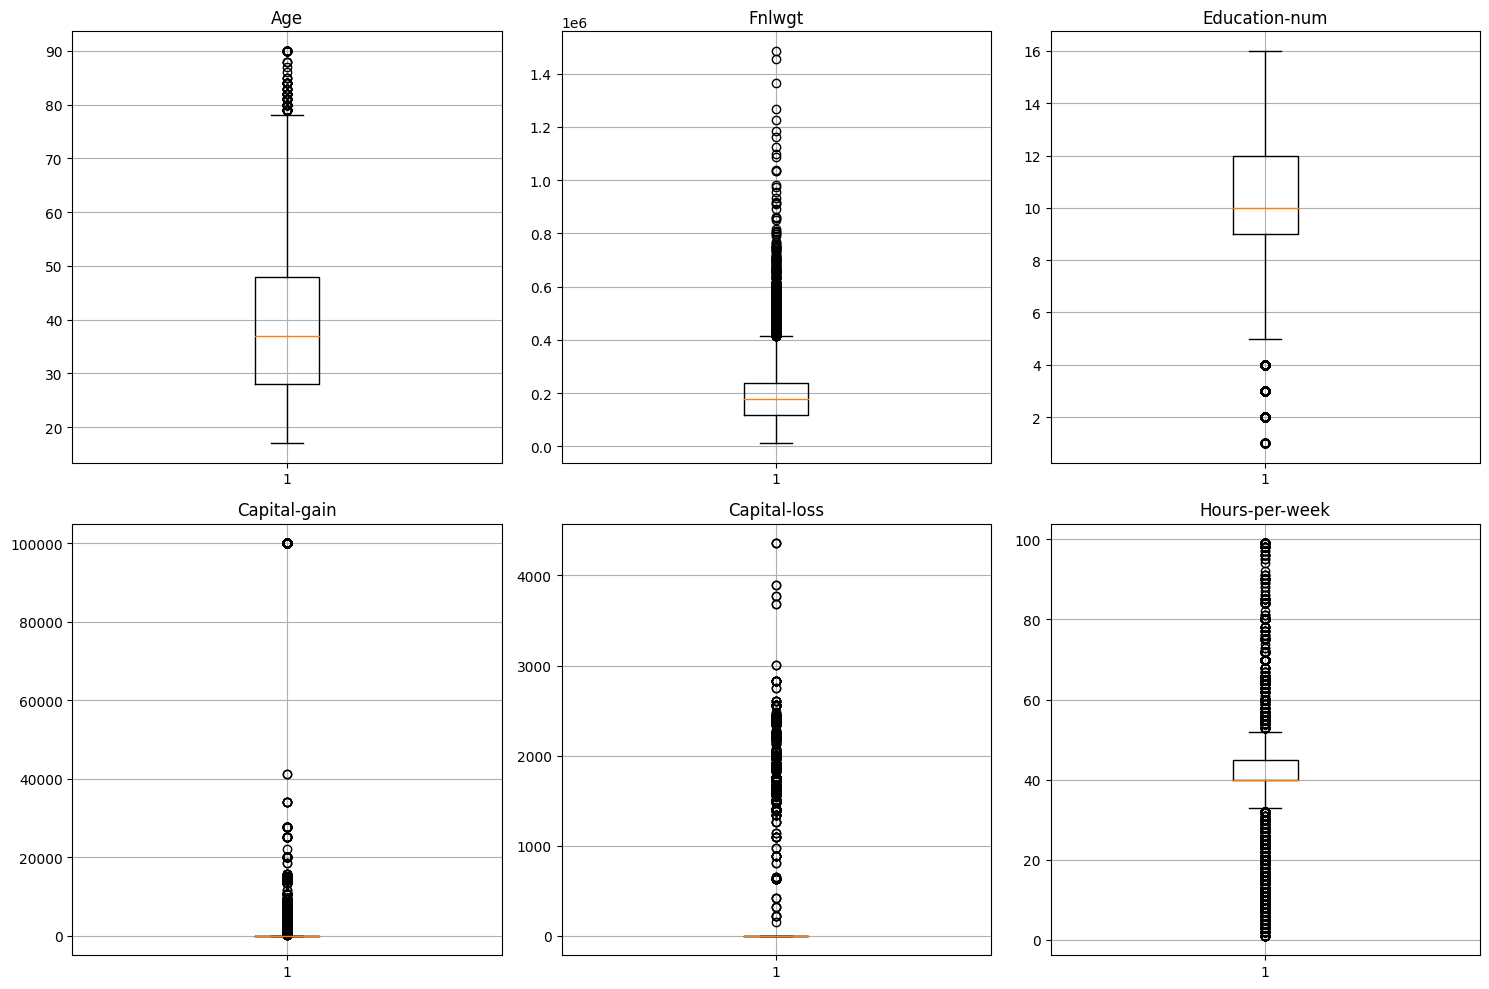

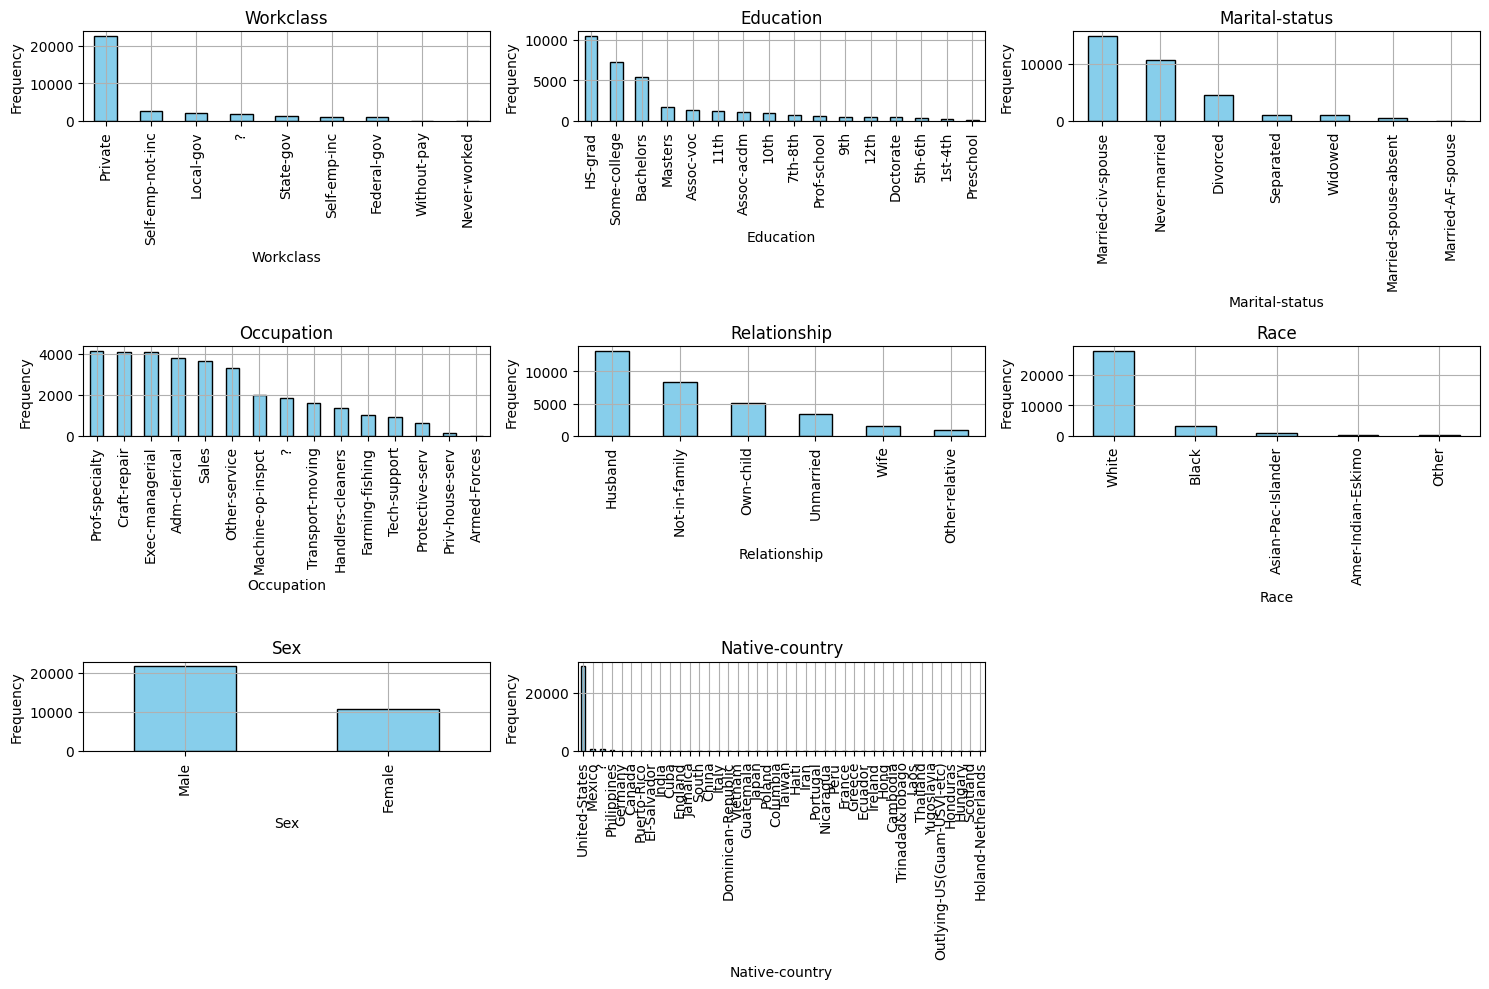

In [6]:
import matplotlib.pyplot as plt

# Box plots for numerical features
numerical_features = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    plt.boxplot(ds_train[feature])
    plt.title(feature.capitalize().replace('_', ' '))
    plt.grid(True)
plt.tight_layout()
plt.show()

# Histograms for categorical features
categorical_features = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(categorical_features, 1):
    plt.subplot(3, 3, i)
    ds_train[feature].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(feature.capitalize().replace('_', ' '))
    plt.xlabel(feature.capitalize().replace('_', ' '))
    plt.ylabel('Frequency')
    plt.grid(True)
plt.tight_layout()
plt.show()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 32417 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32417 non-null  int64 
 1   workclass       32417 non-null  object
 2   fnlwgt          32417 non-null  int64 
 3   education       32417 non-null  object
 4   education-num   32417 non-null  int64 
 5   marital-status  32417 non-null  object
 6   occupation      32417 non-null  object
 7   relationship    32417 non-null  object
 8   race            32417 non-null  object
 9   sex             32417 non-null  object
 10  capital-gain    32417 non-null  int64 
 11  capital-loss    32417 non-null  int64 
 12  hours-per-week  32417 non-null  int64 
 13  native-country  32417 non-null  object
 14  income          32417 non-null  object
dtypes: int64(6), object(9)
memory usage: 4.0+ MB
None


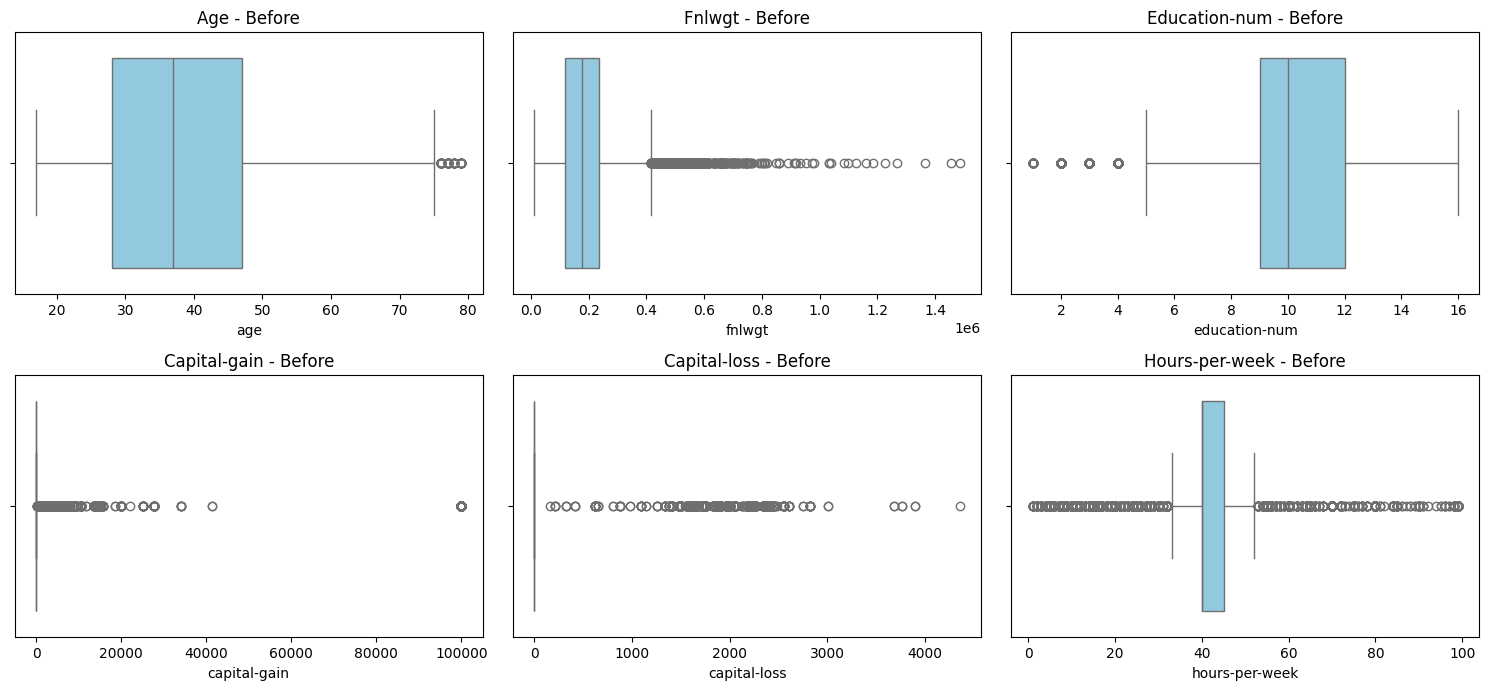

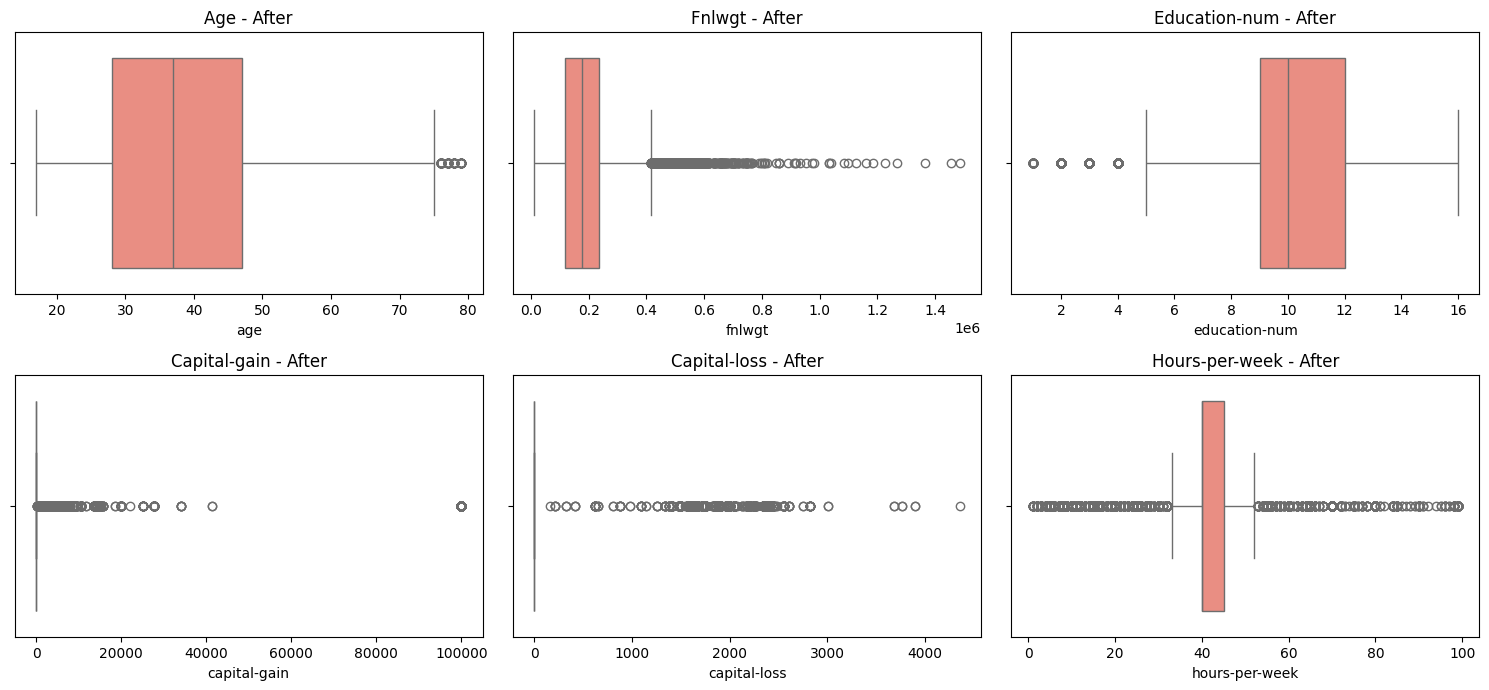

In [7]:
# cleaning
import numpy as np
from scipy import stats

# missing values
ds_train.dropna(inplace=True)

# duplicate entries
ds_train.drop_duplicates(inplace=True)

# converting to lowercase
ds_train = ds_train.apply(lambda x: x.str.lower() if x.dtype == "object" else x)

# Remove outliers in 'age' feature
ds_train = ds_train[(np.abs(stats.zscore(ds_train['age'])) < 3)]

print(ds_train.info())

plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=ds_train[feature], color='skyblue')
    plt.title(f'{feature.capitalize().replace("_", " ")} - Before')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=ds_train[feature], color='salmon')
    plt.title(f'{feature.capitalize().replace("_", " ")} - After')
plt.tight_layout()
plt.show()

['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
   age         workclass  fnlwgt  education  education-num  \
0   39         state-gov   77516  bachelors             13   
1   50  self-emp-not-inc   83311  bachelors             13   
2   38           private  215646    hs-grad              9   
3   53           private  234721       11th              7   
4   28           private  338409  bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       never-married       adm-clerical  not-in-family  white    male   
1  married-civ-spouse    exec-managerial        husband  white    male   
2            divorced  handlers-cleaners  not-in-family  white    male   
3  married-civ-spouse  handlers-cleaners        husband  black    male   
4  married-civ-spouse     prof-specialty           wif

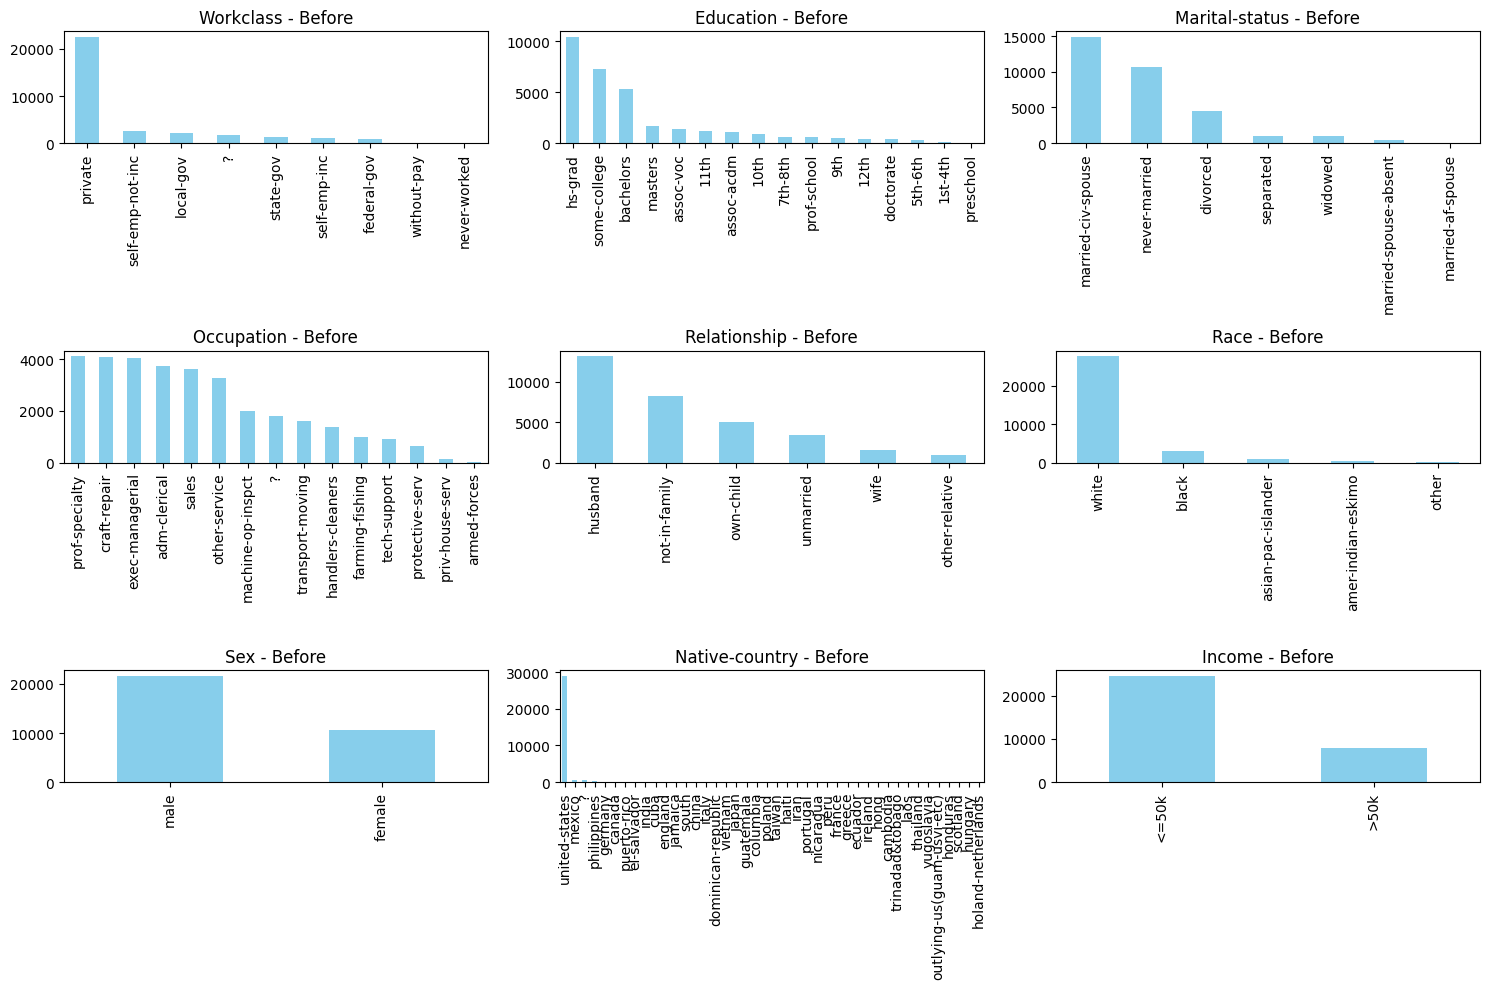

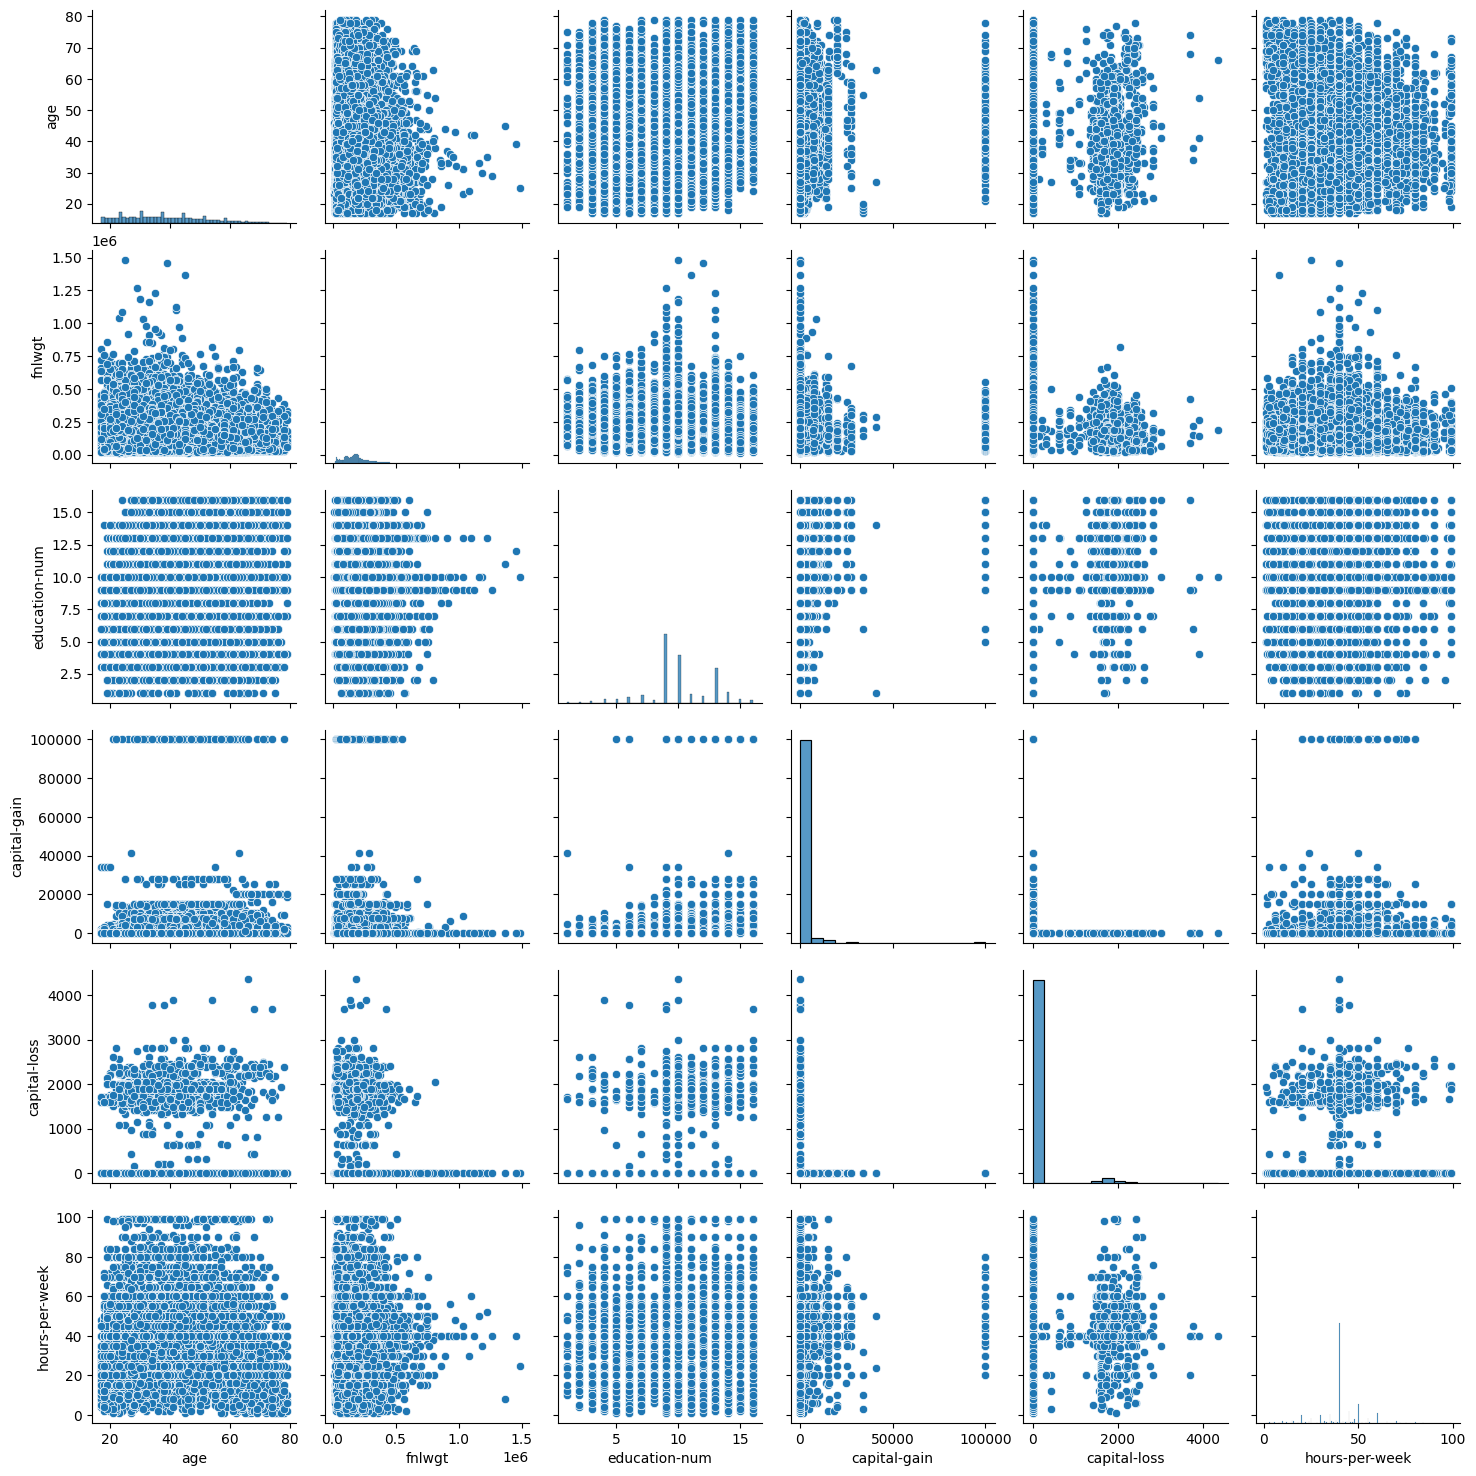

In [8]:
# feature engineering

#seperating categorical features
categorical_features = list(ds_train.select_dtypes(include=['object']).columns)
print(categorical_features)

#seperating numerical features
numerical_features = list(ds_train.select_dtypes(include=['int64', 'float64']).columns)
print(numerical_features)

print(ds_train.head())

plt.figure(figsize=(15, 10))
for i, feature in enumerate(categorical_features, 1):
    plt.subplot(3, 3, i)
    ds_train[feature].value_counts().plot(kind='bar', color='skyblue')
    plt.title(f'{feature.capitalize().replace("_", " ")} - Before')
plt.tight_layout()
plt.show()

sns.pairplot(ds_train[numerical_features])
plt.show()

Test Data

In [9]:
# load testing dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

ds_test = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True, skiprows=1) # avoiding "|1x3 Cross validator" string
print(ds_test.info())
print(ds_test.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16281 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16281 non-null  int64 
 1   workclass       16281 non-null  object
 2   fnlwgt          16281 non-null  int64 
 3   education       16281 non-null  object
 4   education-num   16281 non-null  int64 
 5   marital-status  16281 non-null  object
 6   occupation      16281 non-null  object
 7   relationship    16281 non-null  object
 8   race            16281 non-null  object
 9   sex             16281 non-null  object
 10  capital-gain    16281 non-null  int64 
 11  capital-loss    16281 non-null  int64 
 12  hours-per-week  16281 non-null  int64 
 13  native-country  16281 non-null  object
 14  income          16281 non-null  object
dtypes: int64(6), object(9)
memory usage: 1.9+ MB
None
   age  workclass  fnlwgt     education  education-num      marital-status  \
0   25    

In [10]:
# cleaning
import numpy as np
from scipy import stats

# convert false dtypes
ds_test['age'] = ds_test['age'].astype(int)
ds_test['fnlwgt'] = ds_test['fnlwgt'].astype(int)
ds_test['education-num'] = ds_test['education-num'].astype(int)
ds_test['capital-gain'] = ds_test['capital-gain'].astype(int)
ds_test['capital-loss'] = ds_test['capital-loss'].astype(int)
ds_test['hours-per-week'] = ds_test['hours-per-week'].astype(int)

# missing values
ds_test.dropna(inplace=True)

# duplicate entries
ds_test.drop_duplicates(inplace=True)

# converting to lowercase
ds_test = ds_test.apply(lambda x: x.str.lower() if x.dtype == "object" else x)

# Remove outliers in 'age' feature
ds_test = ds_test[(np.abs(stats.zscore(ds_test['age'])) < 3)]

print(ds_test.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16227 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16227 non-null  int64 
 1   workclass       16227 non-null  object
 2   fnlwgt          16227 non-null  int64 
 3   education       16227 non-null  object
 4   education-num   16227 non-null  int64 
 5   marital-status  16227 non-null  object
 6   occupation      16227 non-null  object
 7   relationship    16227 non-null  object
 8   race            16227 non-null  object
 9   sex             16227 non-null  object
 10  capital-gain    16227 non-null  int64 
 11  capital-loss    16227 non-null  int64 
 12  hours-per-week  16227 non-null  int64 
 13  native-country  16227 non-null  object
 14  income          16227 non-null  object
dtypes: int64(6), object(9)
memory usage: 2.0+ MB
None


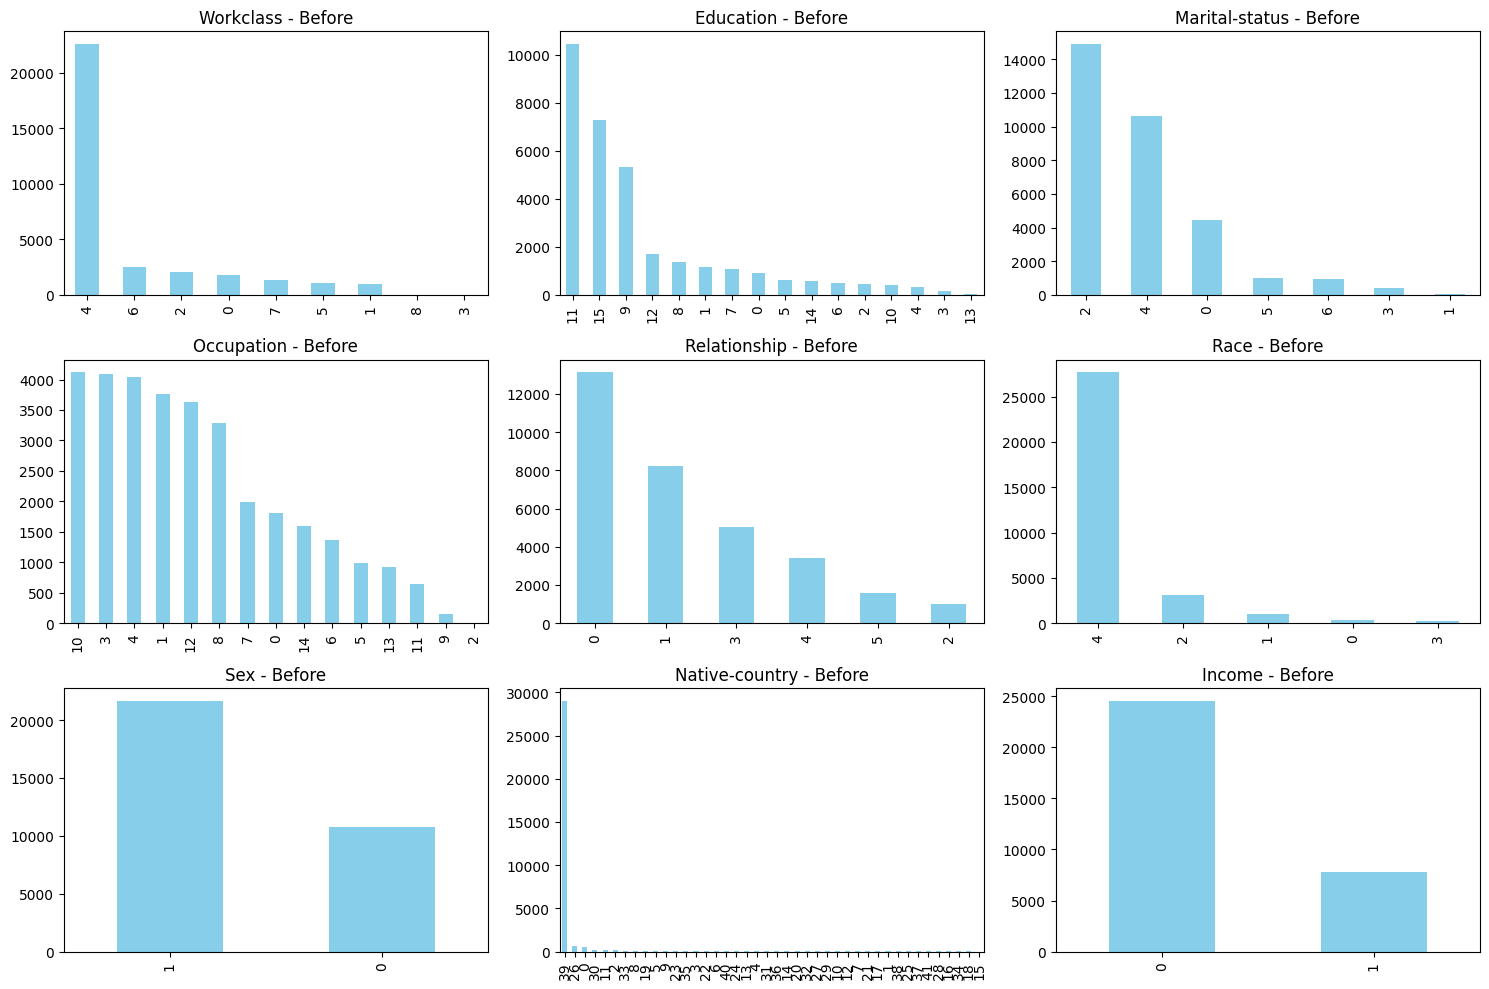

In [11]:
# Label Encoding

le = preprocessing.LabelEncoder()
for i in categorical_features:
    ds_train[i] = le.fit_transform(ds_train[i])
    ds_test[i] = le.fit_transform(ds_test[i])

ds_train.head()

plt.figure(figsize=(15, 10))
for i, feature in enumerate(categorical_features, 1):
    plt.subplot(3, 3, i)
    ds_train[feature].value_counts().plot(kind='bar', color='skyblue')
    plt.title(f'{feature.capitalize().replace("_", " ")} - Before')
plt.tight_layout()
plt.show()

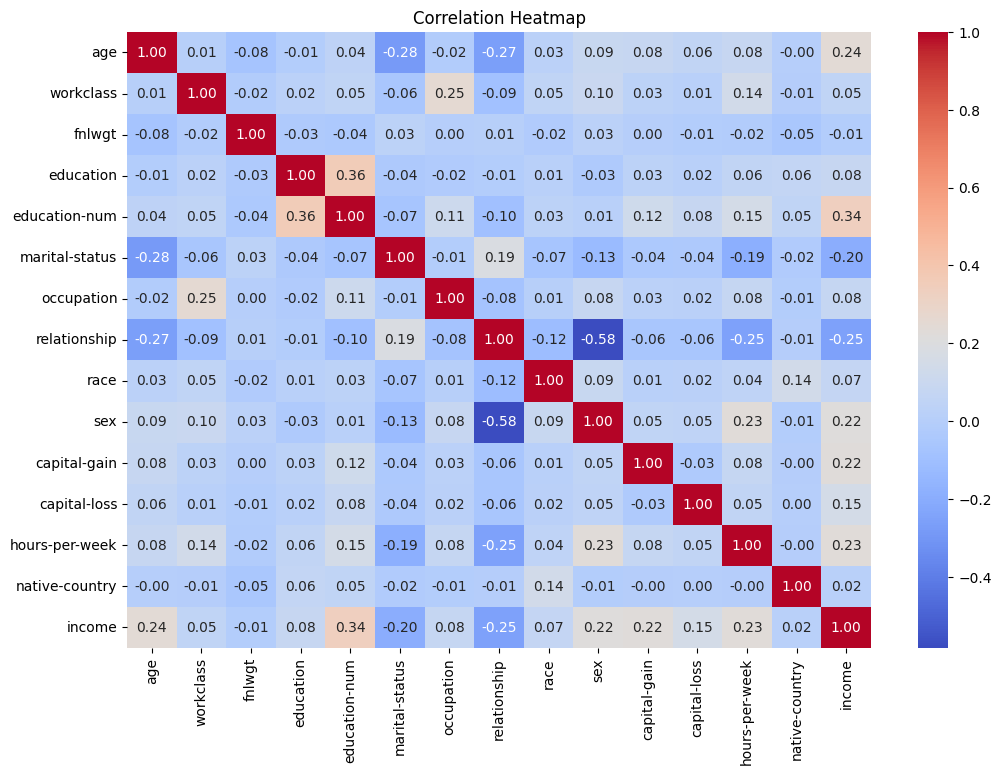

In [12]:
ds_test.head()

# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(ds_train.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [13]:
# test train split

X = ds_train.drop('income', axis=1)
y = ds_train['income']

print("Training set:")
print(X.head())


Training set:
   age  workclass  fnlwgt  education  education-num  marital-status  \
0   39          7   77516          9             13               4   
1   50          6   83311          9             13               2   
2   38          4  215646         11              9               0   
3   53          4  234721          1              7               2   
4   28          4  338409          9             13               2   

   occupation  relationship  race  sex  capital-gain  capital-loss  \
0           1             1     4    1          2174             0   
1           4             0     4    1             0             0   
2           6             1     4    1             0             0   
3           6             0     2    1             0             0   
4          10             5     2    0             0             0   

   hours-per-week  native-country  
0              40              39  
1              13              39  
2              40             

In [14]:
from sklearn.metrics import classification_report

naive_bayes = GaussianNB()
naive_bayes.fit(X, y)

# Random Forest Classifier
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X, y)

# Predictions for Naive Bayes
naive_bayes_pred = naive_bayes.predict(ds_test.drop('income', axis=1))

# Predictions for Random Forest Classifier
random_forest_pred = random_forest.predict(ds_test.drop('income', axis=1))

# Classification report for Naive Bayes on test data
print("Classification Report - Naive Bayes on Test Data:")
print(classification_report(ds_test['income'], naive_bayes_pred))

# Classification report for Random Forest Classifier on test data
print("\nClassification Report - Random Forest on Test Data:")
print(classification_report(ds_test['income'], random_forest_pred))


Classification Report - Naive Bayes on Test Data:
              precision    recall  f1-score   support

           0       0.81      0.95      0.88     12392
           1       0.64      0.31      0.41      3835

    accuracy                           0.79     16227
   macro avg       0.73      0.63      0.64     16227
weighted avg       0.77      0.79      0.77     16227


Classification Report - Random Forest on Test Data:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91     12392
           1       0.74      0.61      0.67      3835

    accuracy                           0.86     16227
   macro avg       0.81      0.77      0.79     16227
weighted avg       0.85      0.86      0.85     16227



[[11729   663]
 [ 2665  1170]]


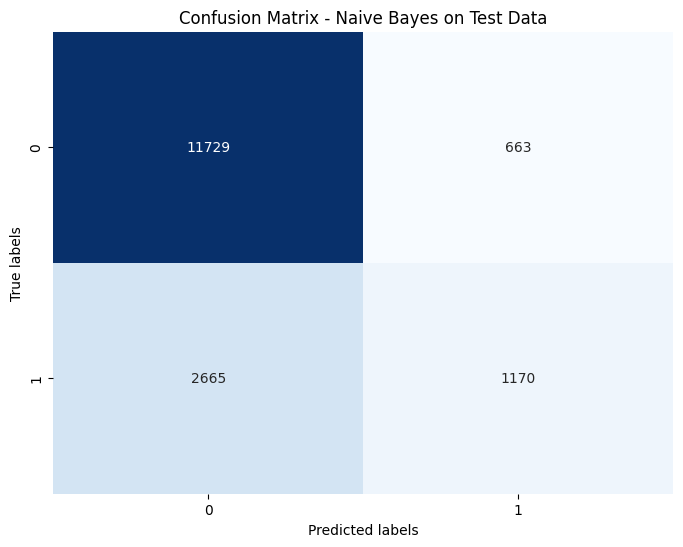

[[11568   824]
 [ 1503  2332]]


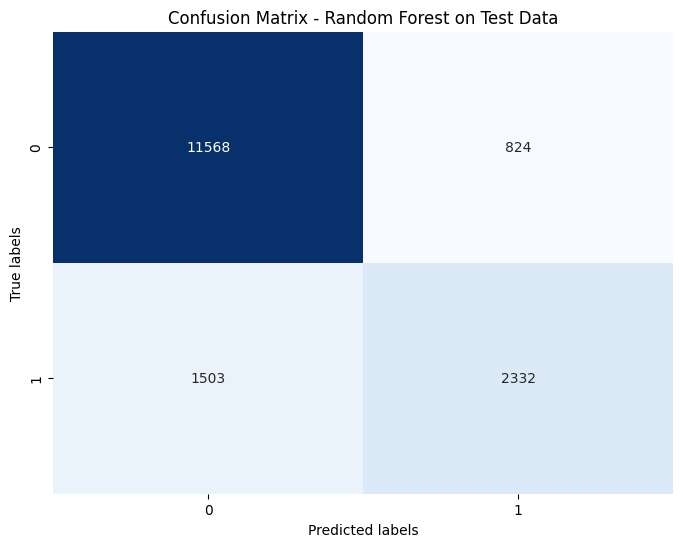

In [15]:

# Calculate confusion matrix for Naive Bayes on test data
cm_nb_test = confusion_matrix(ds_test['income'], naive_bayes_pred)
print(cm_nb_test)
# Plot confusion matrix for Naive Bayes on test data
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb_test, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - Naive Bayes on Test Data')
plt.show()

# Calculate confusion matrix for Random Forest Classifier on test data
cm_rf_test = confusion_matrix(ds_test['income'], random_forest_pred)
print(cm_rf_test)
# Plot confusion matrix for Random Forest Classifier on test data
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf_test, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - Random Forest on Test Data')
plt.show()

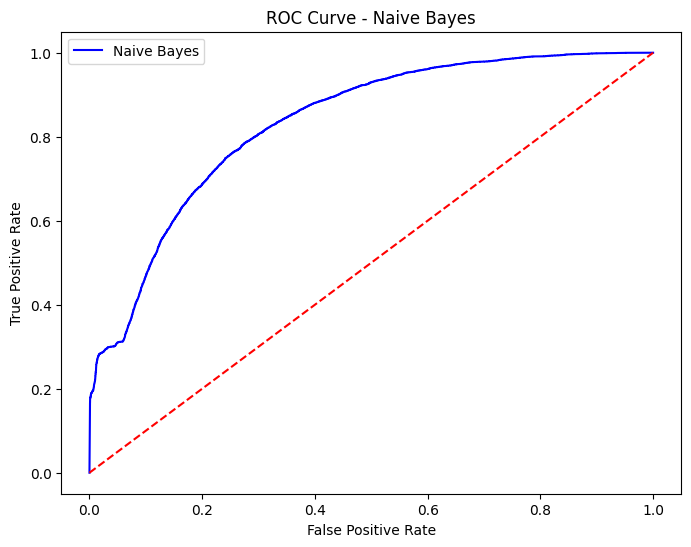

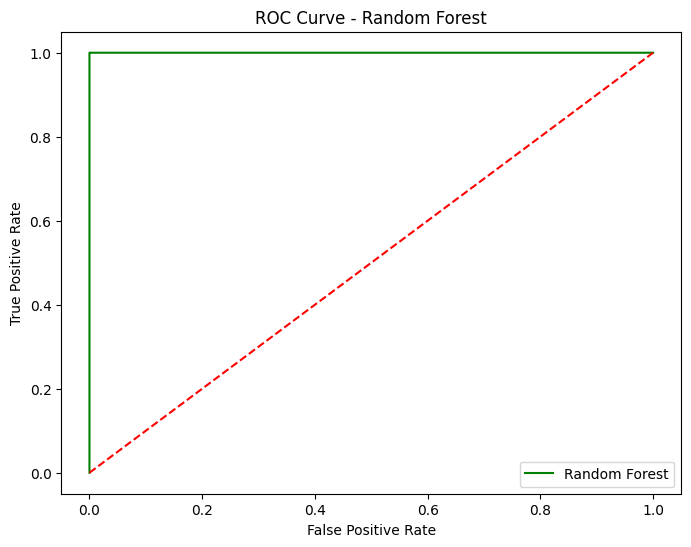

In [17]:
from sklearn.metrics import roc_curve, roc_auc_score

naive_bayes_probs = naive_bayes.predict_proba(X)[:, 1]
fpr_nb, tpr_nb, _ = roc_curve(y, naive_bayes_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr_nb, tpr_nb, color='blue', label='Naive Bayes')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')
plt.legend()
plt.show()

random_forest_probs = random_forest.predict_proba(X)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y, random_forest_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='green', label='Random Forest')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()


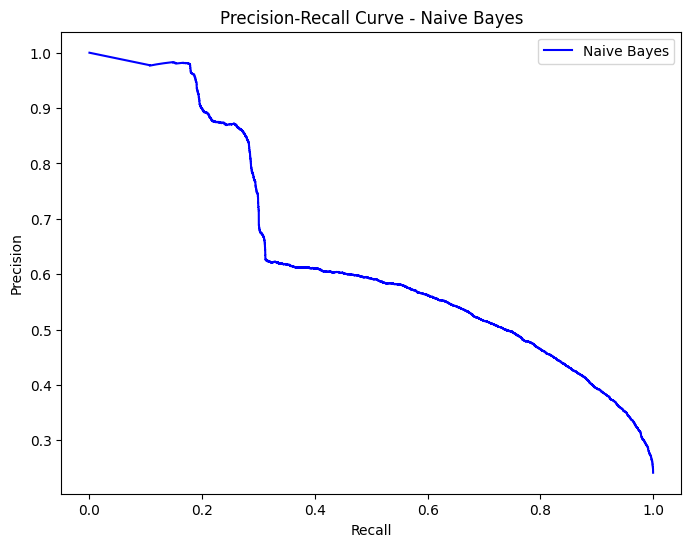

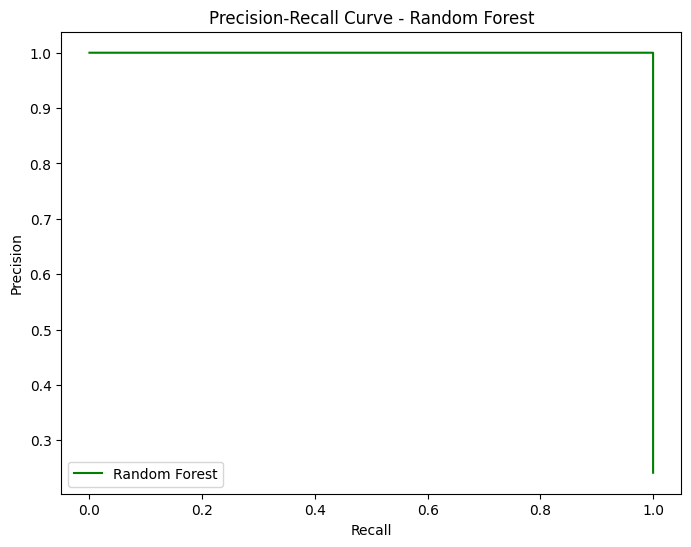

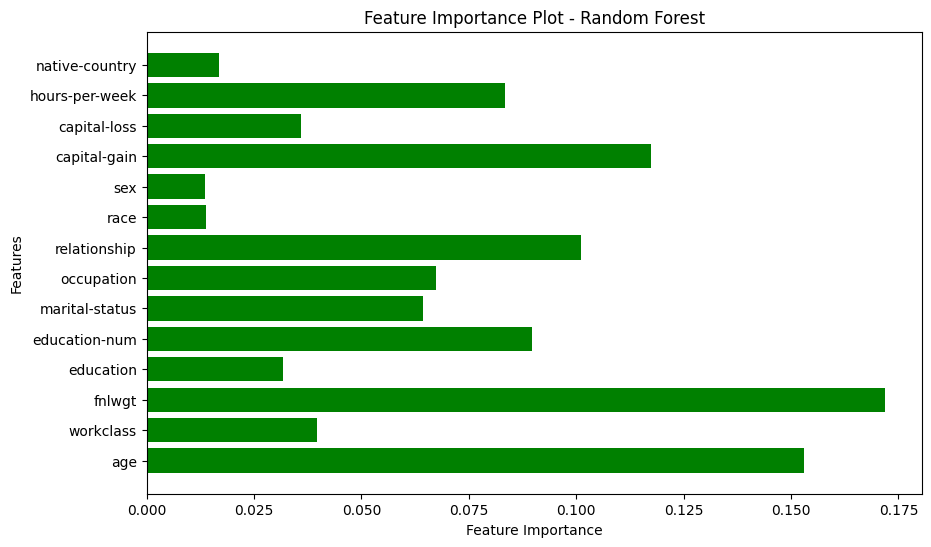

In [18]:
# Precision-Recall curve for Naive Bayes
from sklearn.metrics import precision_recall_curve

precision_nb, recall_nb, _ = precision_recall_curve(y, naive_bayes_probs)

plt.figure(figsize=(8, 6))
plt.plot(recall_nb, precision_nb, color='blue', label='Naive Bayes')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Naive Bayes')
plt.legend()
plt.show()

# Precision-Recall curve for Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y, random_forest_probs)

plt.figure(figsize=(8, 6))
plt.plot(recall_rf, precision_rf, color='green', label='Random Forest')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Random Forest')
plt.legend()
plt.show()

# Feature importance plot for Random Forest
plt.figure(figsize=(10, 6))
plt.barh(X.columns, random_forest.feature_importances_, color='green')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importance Plot - Random Forest')
plt.show()